In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
import os
os.makedirs("figures", exist_ok=True)

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [2]:
df2 = pd.concat([pd.read_csv(f) for f in 
                glob("../data/*.csv") ])

In [5]:
df2 = df2[~df2.title.isna()]

In [3]:
len(df2)

130121

## Time Series

In [7]:
df2["yearmonth"] = df2["publish_date"].apply(lambda x: x[:7])
df2.to_pickle("df2.pkl")


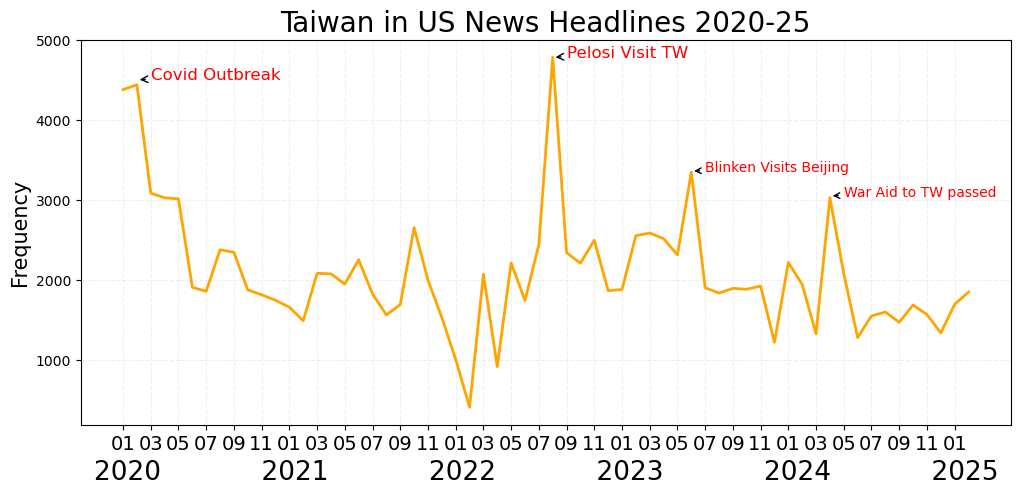

In [22]:
x = df2.yearmonth.value_counts().reset_index()
x.columns = ["yearmonth", "freq"]
x = x.sort_values("yearmonth")
x = x[x['yearmonth'] != '2025-03']

plt.figure(figsize=(12,5))
plt.title("Taiwan in US News Headlines 2020-25",fontsize=20)
plt.ylabel("Frequency",fontsize=15)
plt.xlabel("Month, Year")


#Pelosi visit text
peak_x = "2022-08"
peak_y = 4780
peak_datetime = pd.to_datetime(peak_x)

new_peak_x = (peak_datetime + pd.DateOffset(months=1)).strftime('%Y-%m')

plt.annotate('Pelosi Visit TW', 
             xy=(peak_x, peak_y),  # Point to annotate (original date)
             xytext=(new_peak_x, peak_y ),  # Position of the text (next month)
             arrowprops=dict(facecolor='black', arrowstyle='->'),  # Optional arrow
             fontsize=12,
             color='Red')

#Covid 
covid_peak_x = "2020-02"
covid_peak_y = 4500

covid_peak_datetime = pd.to_datetime(covid_peak_x)
covid_new_peak_x = (covid_peak_datetime + pd.DateOffset(months=1)).strftime('%Y-%m')

plt.annotate('Covid Outbreak', 
             xy=(covid_peak_x, covid_peak_y),  # Point to annotate (original date)
             xytext=(covid_new_peak_x, covid_peak_y ),  # Position of the text (next month)
             arrowprops=dict(facecolor='black', arrowstyle='->'),  # Optional arrow
             fontsize=12,
             color='Red')


#Blinken 
B_peak_x = "2023-06"
B_peak_y = 3360

B_peak_datetime = pd.to_datetime(B_peak_x)
B_new_peak_x = (B_peak_datetime + pd.DateOffset(months=1)).strftime('%Y-%m')

plt.annotate('Blinken Visits Beijing', 
             xy=(B_peak_x, B_peak_y),  # Point to annotate (original date)
             xytext=(B_new_peak_x, B_peak_y ),  # Position of the text (next month)
             arrowprops=dict(facecolor='black', arrowstyle='->'),  # Optional arrow
             fontsize=10,
             color='Red')

#aid
a_peak_x = "2024-04"
a_peak_y = 3050

a_peak_datetime = pd.to_datetime(a_peak_x)
a_new_peak_x = (a_peak_datetime + pd.DateOffset(months=1)).strftime('%Y-%m')

plt.annotate('War Aid to TW passed', 
             xy=(a_peak_x, a_peak_y),  # Point to annotate (original date)
             xytext=(a_new_peak_x, a_peak_y ),  # Position of the text (next month)
             arrowprops=dict(facecolor='black', arrowstyle='->'),  # Optional arrow
             fontsize=10,
             color='Red')


plt.grid(True,alpha=0.2, linestyle='--')
plt.plot(x.yearmonth, x.freq, linewidth=2,color="orange")

# plt.xticks(rotation=90)
plt.xticks(x.yearmonth.values[::2], [y[-2:] for y in x.yearmonth][::2], fontsize=14)
label_w_year = (" "*12).join(["2020", "2021", "2022", "2023", "2024","2025"])
plt.xlabel(label_w_year, fontsize=19)
""

plt.savefig('figures/Frequency.jpg',dpi=300)


In [2]:
df2[df2.yearmonth == "2024-04"]["title"].value_counts().iloc[:15] 
#used this code to determine the event associated with each peak in news coverage 

## Vader Sentiment

In [5]:
sent_obj = SentimentIntensityAnalyzer()
sample_sentence = "Taiwan strengthens ties with the US."
sentiment_example = sent_obj.polarity_scores(sample_sentence)

In [8]:
%%time
sentiment_scores=[]

for t in df2.title:
    sentiment_scores.append(sent_obj.polarity_scores(t))

df2["sentiment_score"] = sentiment_scores

CPU times: user 1.95 s, sys: 11.1 ms, total: 1.96 s
Wall time: 1.97 s


In [10]:
%%time
df2["sentiment_score"] = df2.title.apply(lambda x: sent_obj.polarity_scores(x))

CPU times: user 1.97 s, sys: 11.6 ms, total: 1.98 s
Wall time: 1.98 s


In [11]:
df2["sentiment_score"].iloc[0]

df2["compound_sent"] = df2.title.apply(lambda x: sent_obj.polarity_scores(x)["compound"])


In [12]:
%%time

df2["compound_sent"] = df2.sentiment_score.apply(lambda x:x["compound"])

CPU times: user 10.1 ms, sys: 1.21 ms, total: 11.3 ms
Wall time: 11.2 ms


In [1]:
df2.to_pickle("df2.pkl")


In [ ]:
# Main visualizstions here

plt.figure(figsize=(7,5))

#China
df2["has China"]=df2.title.str.lower().str.contains("china")
x_china=df2.groupby("has China")["compound_sent"].agg(["mean", "sem","count"]).reset_index()
n = x_china.iloc[1]["count"]
plt.errorbar([0,1], x_china["mean"], yerr=x_china["sem"]*2.56, ecolor="red", label= "China (n={})".format(n))

# TSMC
df2["has tsmc"]=df2.title.str.lower().str.contains("tsmc")
xxx=df2.groupby("has tsmc")["compound_sent"].agg(["mean", "sem","count"]).reset_index()
q = xxx.iloc[1]["count"]
plt.errorbar([0,1], xxx["mean"], yerr=xxx["sem"]*2.56, ecolor="red", label="TSMC (n={})".format(q))

# Biden
df2["has biden"]=df2.title.str.lower().str.contains("biden")
x_biden=df2.groupby("has biden")["compound_sent"].agg(["mean", "sem","count"]).reset_index()
n = x_biden.iloc[1]["count"]
plt.errorbar([0,1], x_biden["mean"], yerr=x_biden["sem"]*2.56, ecolor="red", label="Biden (n={})".format(n))

# Trump
df2["has trump"]=df2.title.str.lower().str.contains("trump")
x_trump=df2.groupby("has trump")["compound_sent"].agg(["mean", "sem","count"]).reset_index()
n = x_trump.iloc[1]["count"]
plt.errorbar([0,1], x_trump["mean"], yerr=x_trump["sem"]*2.56, ecolor="red", label="Trump (n={})".format(n))

# Xi
df2["has xi"]=df2.title.str.lower().str.contains(r"\bxi\b")
x_xi=df2.groupby("has xi")["compound_sent"].agg(["mean", "sem","count"]).reset_index()
n = x_xi.iloc[1]["count"]
plt.errorbar([0,1], x_xi["mean"], yerr=x_xi["sem"]*2.56, ecolor="red", label="Xi (n={})".format(n))

# Pelosi
df2["has pelosi"]=df2.title.str.lower().str.contains("pelosi")
x_pelosi=df2.groupby("has pelosi")["compound_sent"].agg(["mean", "sem","count"]).reset_index()
n = x_pelosi.iloc[1]["count"]
plt.errorbar([0,1], x_pelosi["mean"], yerr=x_pelosi["sem"]*2.56, ecolor="red", label="Pelosi (n={})".format(n))


# Aesthetics here

plt.ylabel("Vader Sentiment", fontsize=20)
plt.title("Headline Sentiments and Topic Inclusion",fontsize=20)
plt.xticks([0,1],["Topic\nnot included", "Topic\nincluded"], fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=12)
plt.savefig('figures/sentiment.jpg',dpi=300)
plt